This notebook contains a test for the function `toNFA` implemented in the notebook `03-Regexp-2-NFA.ipynb`.
In order to write regular expressions conveniently, we need the parser implemented in `RegExp-Parser.ipynb`.

In [1]:
#use "../lib/nb.ml";;
run_notebook "03-Regexp-2-NFA.ipynb";;
run_notebook "RegExp-Parser.ipynb"

- : unit = ()
Findlib has been successfully loaded. Additional directives:
  #require "package";;      to load a package
  #list;;                   to list the available packages
  #camlp4o;;                to load camlp4 (standard syntax)
  #camlp4r;;                to load camlp4 (revised syntax)
  #predicates "p,q,...";;   to set these predicates
  Topfind.reset();;         to force that packages will be reloaded
  #thread;;                 to enable threads

- : unit = ()
- : unit = ()
val lib_dir : string = "../lib"
val loaded_libs : (string, unit) Hashtbl.t = <abstr>
val load_lib : string -> unit = <fun>


- : unit = ()


- : unit = ()


**Note:** The function `run_notebook` executes all cells of a notebook, just like the magic command `%run`.  In
contrast to *basedpyright*, which analyzes every notebook on its own, the OCaml compiler knows all definitions
of the loaded notebooks, so every cell of this notebook is type checked completely.

If the regular expression `r` that is defined below has been written in the style of the lecture notes, it would read:
$$\texttt{a}^* \cdot \texttt{b} \cdot \texttt{a}^*$$

In [2]:
let r = parse "a*ba*"

val r : regexp =
  Product (Product (Star (Char 'a'), Char 'b'), Star (Char 'a'))


In [3]:
let converter = regExp2NFA (FSet.of_list [ 'a'; 'b' ])

val converter : regExp2NFA = {alphabet = {'a', 'b'}; stateCount = 0}


We use `converter` to create an <span style="font-variant:small-caps;">NFA</span>  that accepts the language 
described by the regular expression `r`.  The method call `converter.toNFA(r)` of Python becomes the function
call `toNFA converter r`.

In [4]:
let nfa = toNFA converter r

val nfa : state nfa =
  {states = {1, 2, 3, 4, 5, 6, 7, 8, 9, 10}; sigma = {'a', 'b'};
   delta =
    {(1, Sym 'a') ↦ {2}, (2, Eps) ↦ {1, 4}, (3, Eps) ↦ {1, 4},
     (4, Eps) ↦ {5}, (5, Sym 'b') ↦ {6}, (6, Eps) ↦ {9}, (7, Sym 'a') ↦ {8},
     (8, Eps) ↦ {7, 10}, (9, Eps) ↦ {7, 10}};
   start = 3; accepting = {10}}


In [5]:
run_notebook "FSM-2-Dot.ipynb"

- : unit = ()


val d : Graphviz.t = <abstr>


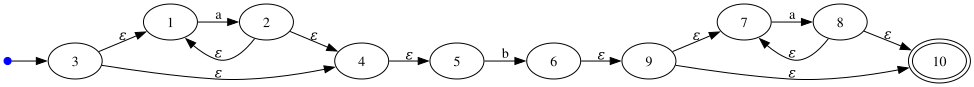

- : unit = ()


In [6]:
let d = nfa2dot ~show:string_of_int nfa
;;
Graphviz.display d

After having constructed an <span style="font-variant:small-caps;">Nfa</span> for the regular expression,
we convert it into a <span style="font-variant:small-caps;">Dfa</span>.

In [7]:
run_notebook "01-NFA-2-DFA.ipynb"

- : unit = ()


In [8]:
let dfa = nfa2dfa nfa

val dfa : state FSet.t dfa =
  {states = {{}, {1, 2, 4, 5}, {1, 3, 4, 5}, {6, 7, 9, 10}, {7, 8, 10}};
   sigma = {'a', 'b'};
   delta =
    {({}, 'a') ↦ {}, ({}, 'b') ↦ {}, ({1, 2, 4, 5}, 'a') ↦ {1, 2, 4, 5},
     ({1, 2, 4, 5}, 'b') ↦ {6, 7, 9, 10}, ({1, 3, 4, 5}, 'a') ↦ {1, 2, 4, 5},
     ({1, 3, 4, 5}, 'b') ↦ {6, 7, 9, 10}, ({6, 7, 9, 10}, 'a') ↦ {7, 8, 10},
     ({6, 7, 9, 10}, 'b') ↦ {}, ({7, 8, 10}, 'a') ↦ {7, 8, 10},
     ({7, 8, 10}, 'b') ↦ {}};
   start = {1, 3, 4, 5}; accepting = {{6, 7, 9, 10}, {7, 8, 10}}}


val d : Graphviz.t = <abstr>
val stateNames : (state FSet.t, string) Dict.t =
  {{} ↦ "S0", {1, 2, 4, 5} ↦ "S1", {1, 3, 4, 5} ↦ "S2", {6, 7, 9, 10} ↦ "S3",
   {7, 8, 10} ↦ "S4"}


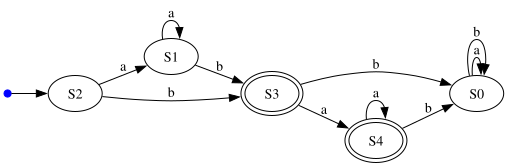

- : unit = ()


In [9]:
let d, stateNames = dfa2dot dfa
;;
Graphviz.display d

Note that the resulting DFA is not minimal, since we can identify some states.

In [10]:
stateNames

- : (state FSet.t, string) Dict.t =
{{} ↦ "S0", {1, 2, 4, 5} ↦ "S1", {1, 3, 4, 5} ↦ "S2", {6, 7, 9, 10} ↦ "S3",
 {7, 8, 10} ↦ "S4"}
